# Do the synergy sectors share neural drive? Intermuscular coherence at 8-30 Hz

`neural_synergies.ipynb` found that NMF "muscle synergies" of the EMG envelopes are **contiguous sectors of the
electrode ring** and are nearly identical on both hands. But anatomy predicts exactly that: neighbouring electrodes
sit over the same muscle and see the same motor units (volume conduction, crosstalk). So the synergies could be a map
of the forearm rather than of the nervous system.

A signature that anatomy cannot easily produce is **shared neural drive**. When two muscles receive common synaptic
input, the spike trains of their motor units fluctuate together, and the rectified EMGs become **coherent** at the
frequencies of that input, classically in the alpha/beta range (8-30 Hz, partly of cortical origin) during steady
contractions (Farina & Negro 2015; Boonstra et al. 2015 on intermuscular coherence networks). Crosstalk, in
contrast, couples the two electrodes at the level of the raw signal, so it should raise coherence **at all
frequencies** and should depend on how close and how electrically coupled the electrodes are, not on synergy
membership.

**Question.** Do electrodes in the same synergy share more 8-30 Hz drive than electrodes in different synergies,
beyond what volume conduction explains?

| | prediction if synergies reflect shared neural drive | what crosstalk alone predicts |
|---|---|---|
| within vs between synergy, **matched ring distance** | within > between at 8-30 Hz | within ≈ between (same distance, same coupling) |
| within vs between, **matched crosstalk index** (raw-signal coherence) | within > between | within ≈ between |
| **spectral shape** of the within-synergy excess | a bump in 8-30 Hz | flat / smooth, no band preference |
| clustering of the 8-30 Hz coherence matrix | recovers the synergies better than the crosstalk matrix does | same groups as the crosstalk matrix |

Data: mini dataset (one user, both hands pooled, `unconstrained` excluded). A warning up front: the tasks are
dynamic finger movements, not the steady holds where intermuscular coherence is normally measured, so a weak or
absent effect would not be surprising.

## Setup

**Locally:** run `uv sync --extra cpu` in the repo root and pick the **semg2pose** kernel. The cell below does nothing.

**On Colab:** select *Runtime → Change runtime type → Runtime version 2026.07* (Python 3.12), optionally with a T4 GPU.
Run the cell below once; when it says so, do *Runtime → Restart session* and run the notebook from the top again.

In [1]:
# Colab only: clone semg2pose (with the emg2pose submodule) and install it. Locally this does nothing.
import os
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    if not (3, 10) <= sys.version_info[:2] < (3, 13):
        raise RuntimeError("Select Runtime > Change runtime type > Runtime version 2026.07 "
                           "(Python 3.12), then run this cell again.")
    REPO_DIR = Path("/content/semg2pose")
    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", "--recurse-submodules",
                        "https://github.com/eljoserass/semg2pose.git", str(REPO_DIR)], check=True)
    try:
        import semg2pose  # noqa: F401  (installed in a previous run + restart)
        print("semg2pose is installed, continue.")
    except ImportError:
        subprocess.run(["bash", str(REPO_DIR / "scripts" / "colab_setup.sh")], check=True,
                       env={**os.environ, "PYTHON": sys.executable})
        print("Installed. Now: Runtime > Restart session, then run the notebook from the top.")
else:
    print("Local kernel:", sys.executable)

Local kernel: /home/rodri/projects/emg2poseneuromatch/semg2pose/.venv/bin/python


In [2]:
import json
import os
import warnings
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import signal
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform
from sklearn.decomposition import NMF
from sklearn.metrics import adjusted_rand_score

from semg2pose.data import FS, download_mini_dataset, list_sessions, load_session
from semg2pose.signals import bandpass, rms_envelope

warnings.filterwarnings("ignore")
DATASET_DIR = download_mini_dataset()
plt.rcParams["figure.dpi"] = 100
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#9AA1B0"
GROUP_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # colorblind-safe categorical order
DIVERGING = LinearSegmentedColormap.from_list("blue_grey_orange", [BLUE, "#e9e8e4", ORANGE])
rng = np.random.default_rng(0)

FS_R, DEC = 500, 4          # rectified EMG is analysed at 500 Hz
WIN, HOP = FS, FS // 2      # 1 s windows (1 Hz resolution), 0.5 s hop
BAND = (8, 30)              # alpha/beta drive
XT_BAND = (120, 250)        # raw-signal band used as the crosstalk yardstick

# Optional: set SEMG2POSE_OUT to a folder to save the key figures and numbers there (unset = nothing is written)
OUT_DIR = os.environ.get("SEMG2POSE_OUT")


def save(fig, name):
    if OUT_DIR:
        (Path(OUT_DIR) / "figs").mkdir(parents=True, exist_ok=True)
        fig.savefig(Path(OUT_DIR) / "figs" / f"coherence_{name}.png", dpi=150, bbox_inches="tight")

Dataset already downloaded: /home/rodri/emg2pose_dataset_mini


## 1. Data: rectified-EMG windows, raw-EMG windows and joint speed

Per recording:

- **Rectified EMG** (the standard input for EMG-EMG coherence): band-pass 20-500 Hz, full-wave rectify, low-pass at
  200 Hz and keep every 4th sample (500 Hz). Rectification turns the amplitude modulation of the EMG, which carries
  the motor-unit firing rhythms, into low-frequency signal content.
- **Raw EMG** at 2 kHz (unrectified). Its coherence between two electrodes at 120-250 Hz comes from the same motor
  unit action potentials reaching both electrodes, i.e. crosstalk. It is our crosstalk yardstick.
- **Joint speed**: Savitzky-Golay derivative of the 20 angles (100 ms local quadratic fit), norm over joints, in deg/s.
  (A first try with a 0.5 s fit hid 3-6 Hz finger wiggles and labelled them as "still".)

Everything is cut into 1 s windows with a 0.5 s hop (Hann taper, 1 Hz resolution), keeping only windows where the
hand tracking never failed. We also keep the 50 Hz linear envelopes for the NMF of section 2.

In [3]:
sos_lp = signal.butter(8, 200, fs=FS, output="sos")        # anti-alias before 2 kHz -> 500 Hz
hann_r, hann_raw = signal.windows.hann(FS_R, sym=False), signal.windows.hann(WIN, sym=False)
freqs = np.fft.rfftfreq(FS_R, 1 / FS_R)                     # rectified EMG: 0-250 Hz
RAW_BINS = slice(20, 501)
freqs_raw = np.fft.rfftfreq(WIN, 1 / FS)[RAW_BINS]          # raw EMG: 20-500 Hz

sessions = list_sessions(DATASET_DIR)
recs = []
for _, row in sessions.iterrows():
    if row.stage == "unconstrained":       # EMG at the noise floor (see neural_synergies.ipynb)
        continue
    emg, angles, ok, meta = load_session(row.path)
    vel = signal.savgol_filter(angles, 201, 2, deriv=1, delta=1 / FS, axis=0)
    speed = np.r_[0, np.cumsum(np.degrees(np.linalg.norm(vel, axis=1)))]
    starts = np.arange(0, len(emg) - WIN + 1, HOP)
    nbad = np.r_[0, np.cumsum(~ok)]
    starts = starts[nbad[starts + WIN] == nbad[starts]]              # fully tracked windows only
    rect = signal.sosfiltfilt(sos_lp, np.abs(bandpass(emg, 20, 500)), axis=0)[::DEC]
    seg = np.stack([rect[s // DEC: s // DEC + FS_R] for s in starts]) if len(starts) else np.zeros((0, FS_R, 16))
    raw = np.stack([emg[s: s + WIN] for s in starts]) if len(starts) else np.zeros((0, WIN, 16))
    seg -= seg.mean(1, keepdims=True)
    raw -= raw.mean(1, keepdims=True)
    recs.append({"stage": row.stage, "side": row.side, "t": starts / FS,
                 "speed": (speed[starts + WIN] - speed[starts]) / WIN,     # mean joint speed in the window
                 "emg_rms": raw.std(1).mean(1),
                 "Xr": np.fft.rfft(seg * hann_r[:, None], axis=1).astype(np.complex64),
                 "Xraw": np.fft.rfft(raw * hann_raw[:, None], axis=1)[:, RAW_BINS].astype(np.complex64),
                 "lin": rms_envelope(bandpass(emg, 20, 450), window_s=0.1)[::40],
                 "lin_ok": ~np.convolve(~ok, np.ones(601), mode="same").astype(bool)[::40]})
print(f"{len(recs)} recordings, {sum(len(r['t']) for r in recs)} tracked 1 s windows (0.5 s hop)")

28 recordings, 2294 tracked 1 s windows (0.5 s hop)


### Choosing "still" and "moving" windows

Intermuscular coherence is normally measured during steady contractions, so the main condition is windows in which
the hand is (relatively) still for the whole second. We first look at how still the hand ever is in these tasks.

In [4]:
all_speed = np.concatenate([r["speed"] for r in recs])
SPEED_STILL, SPEED_FAST = np.percentile(all_speed, [20, 80])
SPEED_STRICT = 150
print("mean joint speed per 1 s window (deg/s, norm over 20 joints): "
      f"10th pct {np.percentile(all_speed, 10):.0f}, median {np.median(all_speed):.0f}, 90th pct {np.percentile(all_speed, 90):.0f}")
print(f"windows below {SPEED_STRICT} deg/s: {(all_speed < SPEED_STRICT).sum()} of {len(all_speed)}")

for r in recs:
    r["still"] = r["speed"] <= SPEED_STILL
    r["strict"] = r["speed"] < SPEED_STRICT
    r["fast_all"] = r["speed"] >= SPEED_FAST
n_still = sum(r["still"].sum() for r in recs)
cand = [(i, j) for i, r in enumerate(recs) for j in np.flatnonzero(r["fast_all"])]
for r in recs:
    r["fast"] = np.zeros(len(r["t"]), bool)
for k in rng.choice(len(cand), n_still, replace=False):          # same number of windows as "still"
    recs[cand[k][0]]["fast"][cand[k][1]] = True

counts = pd.DataFrame([{"stage": r["stage"], "side": r["side"], "still": r["still"].sum(), "fast": r["fast"].sum()}
                       for r in recs]).groupby("stage")[["still", "fast"]].sum()
print(counts.sort_values("still", ascending=False).to_string())
rms = {c: np.median(np.concatenate([r["emg_rms"][r[c]] for r in recs])) for c in ["still", "fast"]}
print(f"\nthresholds: still <= {SPEED_STILL:.0f} deg/s (slowest 20 %), fast >= {SPEED_FAST:.0f} deg/s (fastest 20 %)")
print(f"windows: still {n_still}, fast {n_still} (drawn from {len(cand)} candidates), strict still (< {SPEED_STRICT}) "
      f"{sum(r['strict'].sum() for r in recs)}")
print(f"median raw EMG RMS: still {rms['still']:.1f}, fast {rms['fast']:.1f} (noise floor = 1)")

mean joint speed per 1 s window (deg/s, norm over 20 joints): 10th pct 179, median 340, 90th pct 700
windows below 150 deg/s: 132 of 2294
                                          still  fast
stage                                                
FingerAbductionSeries                        92     0
HookEmHornsOKScissors                        88     0
WristFlexionAbduction                        73     0
ThumbsUpDownThumbRotationsCWCCWP             46     1
IndividualFingerPointingSnap                 46     7
ThumbsSwipesWholeHand                        39    24
CountingUpDownFaceSideAway                   29    16
ShakaVulcanPeace                             14    14
FingerWigglingSpreading                      14    49
FingerPinchesSingleFingerPinchesMultiple     11     1
TwoHandedFreeStyle                            7   166
FingerFreeform                                0    65
HandClawGraspFlicks                           0    77
OneHandedFreeStyle                            0    3

**What we see.** The hand is almost never still in these tasks: the median 1 s window moves at 340 deg/s (norm over 20 joints),
and only 132 of 2,294 windows stay below 150 deg/s. So "still" here means **the slowest 20 % of windows**
(≤ 225 deg/s, roughly ≤ 50 deg/s per joint), 459 windows (~5 min of unique data, since overlapping windows share half their samples). The muscles are
active in them (median EMG RMS 20× the noise floor, vs 31× in fast windows): the hand holds or slowly adjusts a
posture, which is the closest this dataset gets to the steady contractions of coherence studies. The 132 strictly
slow windows (< 150 deg/s) are kept as a check.

Caveat: the slow and fast windows come from **different tasks** (slow: finger abduction, HookEm/OK/scissors, wrist
flexion; fast: two-handed free style, claw grasps, finger free form). The fastest 20 % happen to be exactly 459
windows too, so the "random subset" keeps all of them.

## 2. Electrode groups: synergies and the palm/back split

As in `neural_synergies.ipynb`: NMF with k = 4 on the linear envelopes (20-450 Hz, 100 ms RMS, 50 Hz), each channel
divided by its standard deviation, pooled over all recordings and both hands. Each channel is assigned to the synergy
that contributes most to it on average (weight × mean activation). The second grouping is plain anatomy: palm side
(channels 0-7, flexors) vs back (8-15, extensors).

synergy group per channel: [0 0 0 1 1 1 1 2 2 2 2 2 3 3 3 3]
share of the dominant synergy per channel: [0.66 0.8  0.64 0.67 0.88 0.74 0.65 0.51 0.72 0.86 0.74 0.56 0.62 0.88
 0.95 0.76]


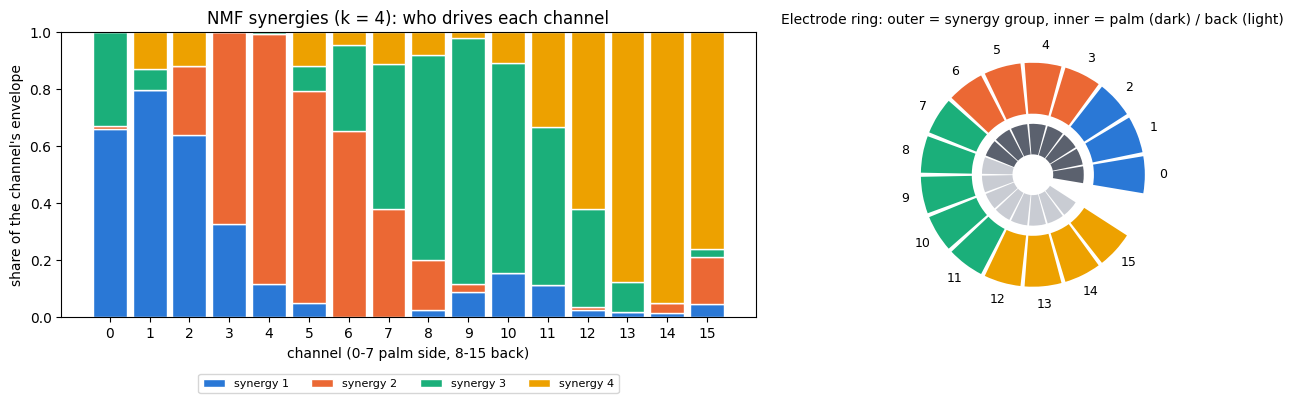

In [5]:
Lin = np.vstack([r["lin"][r["lin_ok"]] for r in recs])
scale_ch = Lin.std(0)
nmf = NMF(n_components=4, init="nndsvda", max_iter=800, random_state=0).fit(Lin / scale_ch)
contrib = nmf.components_ * nmf.transform(Lin / scale_ch).mean(0)[:, None]   # (synergy, channel)
share = contrib / contrib.sum(0)
dominant = share.argmax(0)
ring_order = list(dict.fromkeys(dominant))                                  # relabel synergies in ring order
groups_syn = np.array([ring_order.index(g) for g in dominant])
share = share[ring_order]
groups_anat = (np.arange(16) >= 8).astype(int)
print("synergy group per channel:", groups_syn)
print("share of the dominant synergy per channel:", np.round(share.max(0), 2))

fig = plt.figure(figsize=(14, 4.2))
ax = fig.add_subplot(1, 2, 1)
bottom = np.zeros(16)
for k in range(4):
    ax.bar(range(16), share[k], bottom=bottom, color=GROUP_COLORS[k], width=0.85, label=f"synergy {k + 1}",
           edgecolor="white", linewidth=1)
    bottom += share[k]
ax.set_xticks(range(16)); ax.set_xlabel("channel (0-7 palm side, 8-15 back)"); ax.set_ylabel("share of the channel's envelope")
ax.set_title("NMF synergies (k = 4): who drives each channel"); ax.legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18))
ax = fig.add_subplot(1, 2, 2, projection="polar")
theta = 2 * np.pi * np.arange(16) / 17                      # the 15 -> 0 gap is drawn wider (see section 4)
ax.bar(theta, np.ones(16), bottom=1.2, width=2 * np.pi / 17 * 0.9, color=[GROUP_COLORS[g] for g in groups_syn])
ax.bar(theta, np.full(16, 0.6), bottom=0.4, width=2 * np.pi / 17 * 0.9, color=["#5b616e" if g == 0 else "#c9ccd3" for g in groups_anat])
for c in range(16):
    ax.text(theta[c], 2.55, str(c), ha="center", va="center", fontsize=9)
ax.set_ylim(0, 2.8); ax.set_xticks([]); ax.set_yticks([]); ax.spines["polar"].set_visible(False)
ax.set_title("Electrode ring: outer = synergy group, inner = palm (dark) / back (light)", fontsize=10)
plt.tight_layout(); plt.show()

**What we see.** The four synergies are again contiguous sectors of the ring: channels 0-2, 3-6, 7-11 and 12-15.
The dominant synergy explains 51-95 % of each channel's envelope (channel 7, on a boundary, is the most mixed at
51 %). Three of the four boundaries (2|3, 6|7, 11|12) fall between ordinary neighbours; the fourth falls on the
15 → 0 gap. The palm/back split cuts synergy 3 (7-11) in two.

## 3. Coherence, its noise level, and the time-shift null

**Estimator.** Magnitude-squared coherence from pooled cross-spectra: for a channel pair (a, b),
C_ab(f) = |Σ_w X_a X_b*|² / (Σ_w |X_a|² · Σ_w |X_b|²), summing over all windows w of a condition (Welch with 1 s
Hann windows, but pooled across recordings). Before pooling, each recording's channels are scaled to unit mean power
so that loud recordings do not dominate.

**Significance.** Two thresholds:

- the standard confidence limit for L independent segments, 1 - 0.05^(1/(L-1)), with L corrected for the 50 % overlap
  of adjacent windows (Welch's formula; the correction is small);
- a **time-shift surrogate**: pair each window of channel a with a window of channel b taken from a different time
  (≥ 5 s apart, never the simultaneous window of the other hand), 200 times. This keeps every signal's spectrum but
  destroys any shared fluctuation, so it gives the bias level of the estimator and an empirical 95 % threshold.

In [6]:
IU = np.triu_indices(16, 1)                       # the 120 channel pairs


def stack(cond, key):
    """Windows of one condition, each recording's channels scaled to unit mean power."""
    Xs, rows = [], []
    for i, r in enumerate(recs):
        m = r[cond]
        if not m.any():
            continue
        X = r[key][m]
        Xs.append(X / np.sqrt((np.abs(X) ** 2).mean((0, 1))))
        rows.append(pd.DataFrame({"rec": i, "stage": r["stage"], "side": r["side"], "t": r["t"][m]}))
    return np.concatenate(Xs), pd.concat(rows, ignore_index=True)


def cross_spec(X, Y=None):
    """Sum over windows of X Y^H: (n, F, 16) -> (F, 16, 16)."""
    Xf = X.transpose(1, 2, 0).astype(np.complex128)
    Yf = Xf if Y is None else Y.transpose(1, 2, 0).astype(np.complex128)
    return Xf @ Yf.conj().transpose(0, 2, 1)


def coherence(S, P=None):
    P = np.real(np.einsum("faa->fa", S)) if P is None else P
    return np.abs(S) ** 2 / (P[:, :, None] * P[:, None, :])


def band_mean(C, lo, hi, f=freqs):
    """Mean over the band, returned as the 120 pair values."""
    return C[(f >= lo) & (f <= hi)].mean(0)[IU]


def effective_L(meta):
    """Number of windows corrected for the 50 % overlap of consecutive Hann windows (Welch 1967)."""
    adjacent = ((meta.rec.diff() == 0) & np.isclose(meta.t.diff(), HOP / FS)).sum()
    return len(meta) ** 2 / (len(meta) + 2 * (1 / 6) ** 2 * adjacent)


def shift_null(X, meta, n_surr=200, min_gap=5.0):
    """Coherence of time-shifted pairings (pairs x frequencies), n_surr times."""
    P = np.real(np.einsum("nfa,nfa->fa", X, X.conj()))
    t, stage = meta.t.values, meta.stage.values
    out = np.empty((n_surr, X.shape[1], len(IU[0])), np.float32)
    for s in range(n_surr):
        perm = rng.permutation(len(X))
        while True:
            bad = np.flatnonzero((stage == stage[perm]) & (np.abs(t - t[perm]) < min_gap))
            if not len(bad):
                break
            for i in bad:
                j = rng.integers(len(X))
                perm[i], perm[j] = perm[j], perm[i]
        out[s] = coherence(cross_spec(X, X[perm]), P)[:, IU[0], IU[1]]
    return out


data = {}
for cond in ["still", "fast", "strict"]:
    X, meta = stack(cond, "Xr")
    Xw, _ = stack(cond, "Xraw")
    data[cond] = {"X": X, "Xw": Xw, "meta": meta, "C": coherence(cross_spec(X)), "Cw": coherence(cross_spec(Xw))}

null = shift_null(data["still"]["X"], data["still"]["meta"])
L_still = len(data["still"]["meta"]); L_eff = effective_L(data["still"]["meta"])
CL = 1 - 0.05 ** (1 / (L_eff - 1))
null_mean = null.mean((0, 2))
null95 = np.percentile(null, 95, axis=(0, 2))                          # per frequency, single pair
null95_band = np.percentile(null[:, (freqs >= BAND[0]) & (freqs <= BAND[1])].mean(1), 95)
print(f"still: L = {L_still} windows (effective {L_eff:.0f}); theoretical 95 % limit per frequency bin {CL:.4f}")
print(f"time-shift null: mean coherence {null_mean[1:151].mean():.4f} (≈ 1/L = {1 / L_still:.4f}), "
      f"95th pct per bin {np.median(null95[1:151]):.4f}, 95th pct of the 8-30 Hz band mean {null95_band:.4f}")

still: L = 459 windows (effective 443); theoretical 95 % limit per frequency bin 0.0067
time-shift null: mean coherence 0.0022 (≈ 1/L = 0.0022), 95th pct per bin 0.0065, 95th pct of the 8-30 Hz band mean 0.0032


### Coherence vs frequency and electrode distance

Before comparing synergies, the overall picture: average coherence spectrum for pairs 1, 2, 3, 4 and ≥ 5 electrodes
apart (ring distance; section 4 explains the wider gap between channels 15 and 0), for the rectified EMG (left) and
for the raw signal (right).

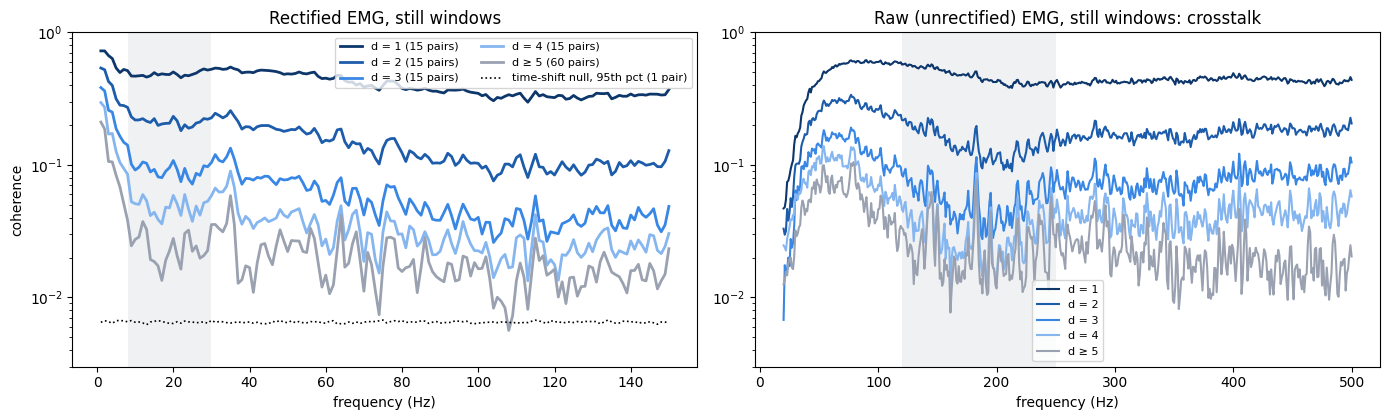

       rectified 1-5 Hz  rectified 8-15 Hz  rectified 15-30 Hz  rectified 8-30 Hz  rectified 30-45 Hz  rectified 55-95 Hz  rectified 100-200 Hz  raw 120-250 Hz
d = 1             0.658              0.477               0.492              0.486               0.519               0.406                 0.344           0.467
d = 2             0.440              0.226               0.209              0.214               0.213               0.135                 0.098           0.147
d = 3             0.288              0.102               0.089              0.094               0.095               0.053                 0.037           0.057
d = 4             0.207              0.055               0.048              0.050               0.051               0.030                 0.022           0.032
d ≥ 5             0.138              0.028               0.023              0.025               0.027               0.019                 0.014           0.023


In [7]:
CIRC = 17          # ring circumference in electrode spacings: the 15 -> 0 gap counts as 2 (section 4)
DIST = np.minimum(np.abs(IU[0] - IU[1]), CIRC - np.abs(IU[0] - IU[1]))
C_st, Cw_st = data["still"]["C"], data["still"]["Cw"]
pair_spec = C_st[:, IU[0], IU[1]]                  # (F, 120)
pair_spec_raw = Cw_st[:, IU[0], IU[1]]
dist_sets = [("d = 1", DIST == 1), ("d = 2", DIST == 2), ("d = 3", DIST == 3), ("d = 4", DIST == 4), ("d ≥ 5", DIST >= 5)]
shades = ["#0d366b", "#1c5cab", "#3987e5", "#86b6ef", GREY]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.3))
fsel = (freqs >= 1) & (freqs <= 150)
for (lab, m), col in zip(dist_sets, shades):
    ax1.plot(freqs[fsel], pair_spec[fsel][:, m].mean(1), color=col, lw=2, label=f"{lab} ({m.sum()} pairs)")
    ax2.plot(freqs_raw, pair_spec_raw[:, m].mean(1), color=col, lw=1.5, label=lab)
ax1.plot(freqs[fsel], null95[fsel], ":", color="k", lw=1.2, label="time-shift null, 95th pct (1 pair)")
ax1.axvspan(*BAND, color=GREY, alpha=0.15, lw=0)
ax1.set_yscale("log"); ax1.set_xlabel("frequency (Hz)"); ax1.set_ylabel("coherence"); ax1.set_ylim(3e-3, 1)
ax1.set_title("Rectified EMG, still windows"); ax1.legend(fontsize=8, ncol=2)
ax2.axvspan(*XT_BAND, color=GREY, alpha=0.15, lw=0)
ax2.set_yscale("log"); ax2.set_xlabel("frequency (Hz)"); ax2.set_ylim(3e-3, 1)
ax2.set_title("Raw (unrectified) EMG, still windows: crosstalk"); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

BANDS = {"1-5": (1, 5), "8-15": (8, 15), "15-30": (15, 30), "8-30": (8, 30), "30-45": (30, 45),
         "55-95": (55, 95), "100-200": (100, 200)}
tab = pd.DataFrame({lab: [band_mean(C_st, *b)[m].mean() for b in BANDS.values()] + [band_mean(Cw_st, *XT_BAND, freqs_raw)[m].mean()]
                    for lab, m in dist_sets}, index=[f"rectified {b} Hz" for b in BANDS] + ["raw 120-250 Hz"]).T
print(tab.round(3).to_string())

**What we see.**

- **The noise level is tiny and everything is far above it.** With L = 459 windows (443 effective) the
  theoretical 95 % limit per bin is 0.0067, and the time-shift surrogates agree (95th percentile 0.0065 per bin, mean
  0.0022 = 1/L, the estimator's bias). Even pairs ≥ 5 electrodes apart have 8-30 Hz coherence 0.025 (8× the band
  threshold of 0.0032). Significance against "no coupling" is therefore not informative here; the question is
  only *which* pairs are coupled *more*.
- **Coherence falls steeply with distance**, in parallel with crosstalk: 8-30 Hz coherence 0.49, 0.21, 0.09, 0.05,
  0.025 for d = 1, 2, 3, 4, ≥ 5, and raw-signal coherence at 120-250 Hz 0.47, 0.15, 0.06, 0.03, 0.02.
- **For the rectified EMG, crosstalk is not flat in frequency.** Every distance shows more coherence at low
  frequencies (d = 1: 0.66 at 1-5 Hz, 0.49 at 8-30 Hz, 0.34 at 100-200 Hz). The raw signal is roughly flat above
  ~60 Hz (right panel; below that the dataset's 40 Hz high-pass removes the signal). The reason: two electrodes that
  see the same motor units see the same *firing times*, and rectification moves that shared timing to low
  frequencies, while differences in action-potential shape between the electrodes decorrelate the high frequencies.
  So "8-30 Hz above the broadband floor" alone cannot separate drive from crosstalk; the comparison has to be
  within vs between synergy at matched distance (section 5).
- Distant pairs show no alpha/beta peak: their coherence falls from 0.21 at 1 Hz to ~0.03 at 8 Hz and then stays
  at a floor of ~0.02 (with a peak at 30-36 Hz, up to 0.06 at 35 Hz, discussed in section 7).

## 4. The crosstalk yardstick and the electrode geometry

**Crosstalk index** of a pair = its raw-signal coherence at 120-250 Hz (still windows). Two uses:

1. **Geometry.** The paper's band has a gap between channels 15 and 0 (ulnar side). The crosstalk index of
   neighbours tells how wide it is in electrode spacings.
2. **A second matching variable.** Ring distance is only a proxy of electrical coupling (skin, fat, tendons vary
   around the wrist). Matching on the measured crosstalk index is the more direct control.

In [8]:
XT = band_mean(Cw_st, *XT_BAND, freqs_raw)
XT_mat = np.zeros((16, 16)); XT_mat[IU] = XT; XT_mat += XT_mat.T; np.fill_diagonal(XT_mat, 1)
lin_d = np.abs(IU[0] - IU[1])
print("crosstalk index vs linear distance (pairs not crossing the gap):",
      {d: round(XT[(lin_d == d)].mean(), 3) for d in range(1, 6)})
print("across the gap: 15-0:", round(XT_mat[15, 0], 3), "| 14-0, 15-1:", round(XT_mat[14, 0], 3), round(XT_mat[15, 1], 3),
      "| 13-0, 14-1, 15-2:", [round(XT_mat[a, b], 3) for a, b in [(13, 0), (14, 1), (15, 2)]])

crosstalk index vs linear distance (pairs not crossing the gap): {1: 0.467, 2: 0.148, 3: 0.059, 4: 0.032, 5: 0.024}
across the gap: 15-0: 0.134 | 14-0, 15-1: 0.033 0.052 | 13-0, 14-1, 15-2: [0.03, 0.023, 0.051]


**Geometry.** Crosstalk between neighbours not crossing the gap is 0.47 (1 spacing apart), 0.15 (2), 0.06 (3).
Across the gap, 15-0 is 0.13 (close to the 2-spacing value) and 14-0 / 15-1 are 0.03 / 0.05 (3-4 spacings). So
the gap is about **two electrode spacings** wide: the ring has a circumference of 17 spacings, and 15-0 counts as
distance 2. Beyond 3-4 spacings the crosstalk index flattens at ~0.02 (a common floor: far-field signal or
common-mode noise), so it cannot rank distant pairs.

## 5. Main test: within- vs between-synergy pairs at matched distance

**Statistic.** For a pair-level quantity v (e.g. 8-30 Hz coherence), Δ = mean over ring distances d of
[mean of v over within-synergy pairs at d − mean over between-synergy pairs at d], weighting each distance by the
harmonic mean of the two pair counts. Only distances where both kinds of pair exist count (d = 1-4 here).

**Uncertainty and null.**

- 95 % CI from a **bootstrap over stages** (the 11 stages with still windows, both hands of a stage together,
  resampled with replacement; cross-spectra are re-pooled each time), 1000 resamples.
- A **contiguous-partition null**: every way of cutting the ring into 4 contiguous sectors of ≥ 2 electrodes. The
  synergy sectors are contiguous by construction, so the right question is whether *their* boundaries are special,
  not whether contiguous groups beat random scatter. p = fraction of partitions with Δ at least as large.

Crosstalk should give Δ ≈ 0 for every frequency band and for the raw-signal crosstalk index. Shared alpha/beta drive
should give Δ > 0 at 8-30 Hz that is larger than Δ at 100-200 Hz and on the crosstalk index.

In [9]:
def matched_diff(v, groups, dist=DIST):
    """Within- minus between-group mean of a pair statistic (last axis = 120 pairs), matched on ring distance."""
    within = groups[IU[0]] == groups[IU[1]]
    num, den = 0.0, 0.0
    for d in np.unique(dist):
        a, b = (dist == d) & within, (dist == d) & ~within
        if a.any() and b.any():
            h = a.sum() * b.sum() / (a.sum() + b.sum())
            num = num + h * (v[..., a].mean(-1) - v[..., b].mean(-1))
            den += h
    return num / den


def contiguous_partitions(n_groups, min_size):
    """All labelings of the 16-electrode ring into n_groups contiguous sectors of >= min_size electrodes."""
    parts = []
    for cuts in combinations(range(16), n_groups):        # cut c = boundary between electrodes c and c+1
        if np.diff(np.r_[cuts, cuts[0] + 16]).min() >= min_size:
            parts.append(np.searchsorted(cuts, np.arange(16)) % n_groups)
    return parts


def pair_quantities(C, Cw):
    q = {f"rectified {b} Hz": band_mean(C, *lims) for b, lims in BANDS.items()}
    q["raw 120-250 Hz (crosstalk index)"] = band_mean(Cw, *XT_BAND, freqs_raw)
    q["excess: 8-30 minus 100-200 Hz"] = q["rectified 8-30 Hz"] - q["rectified 100-200 Hz"]
    return q


def crosstalk_adjusted(v, xt, groups, dmax=4):
    """Within-synergy coefficient of z(v) ~ 1 + z(xt) + z(xt)^2 + within, on pairs with d <= dmax (z = atanh sqrt)."""
    m = DIST <= dmax
    z, x = np.arctanh(np.sqrt(v[m])), np.arctanh(np.sqrt(xt[m]))
    within = (groups[IU[0]] == groups[IU[1]])[m].astype(float)
    A = np.c_[np.ones(m.sum()), x, x ** 2, within]
    return np.linalg.lstsq(A, z, rcond=None)[0][3]


def stage_sums(cond):
    d = data[cond]; stages = d["meta"].stage.unique()
    xt_bins = (freqs_raw >= XT_BAND[0]) & (freqs_raw <= XT_BAND[1])
    S = np.stack([cross_spec(d["X"][(d["meta"].stage == s).values]) for s in stages])
    Sw = np.stack([cross_spec(d["Xw"][(d["meta"].stage == s).values][:, xt_bins]) for s in stages])
    return S, Sw


F_MAX = 150
def bootstrap(cond, groups_list, n_boot=1000):
    """Stage bootstrap of matched differences: band quantities, difference spectrum, crosstalk-adjusted effect."""
    S, Sw = stage_sums(cond)
    out = {"bands": [], "spec": [], "adj": []}
    for _ in range(n_boot):
        w = np.bincount(rng.integers(0, len(S), len(S)), minlength=len(S)).astype(float)
        C = coherence(np.tensordot(w, S, axes=1)); Cw = coherence(np.tensordot(w, Sw, axes=1))
        xt = Cw.mean(0)[IU]
        q = {f"rectified {b} Hz": band_mean(C, *lims) for b, lims in BANDS.items()}
        q["raw 120-250 Hz (crosstalk index)"] = xt
        q["excess: 8-30 minus 100-200 Hz"] = q["rectified 8-30 Hz"] - q["rectified 100-200 Hz"]
        out["bands"].append([{k: matched_diff(v, g) for k, v in q.items()} for g in groups_list])
        out["spec"].append([matched_diff(C[: F_MAX + 1, IU[0], IU[1]], g) for g in groups_list])
        out["adj"].append([crosstalk_adjusted(q["rectified 8-30 Hz"], xt, g) for g in groups_list])
    return out


def delta_table(cond, groups, gi, boot, partitions):
    q = pair_quantities(data[cond]["C"], data[cond]["Cw"])
    rows = []
    for k, v in q.items():
        obs = matched_diff(v, groups)
        bs = np.array([b[gi][k] for b in boot["bands"]])
        nul = np.array([matched_diff(v, p) for p in partitions])
        w = groups[IU[0]] == groups[IU[1]]
        rows.append({"quantity": k, "within (d≤4)": v[w & (DIST <= 4)].mean(), "between (d≤4)": v[~w & (DIST <= 4)].mean(),
                     "Δ matched": obs, "CI low": np.percentile(bs, 2.5), "CI high": np.percentile(bs, 97.5),
                     "p (contiguous null)": (nul >= obs - 1e-12).mean()})
    return pd.DataFrame(rows).set_index("quantity")


parts4 = contiguous_partitions(4, 2)
parts2 = contiguous_partitions(2, 4)
boot_still = bootstrap("still", [groups_syn, groups_anat])
res_syn = delta_table("still", groups_syn, 0, boot_still, parts4)
print(f"{len(parts4)} contiguous 4-sector partitions in the null; stage bootstrap over "
      f"{data['still']['meta'].stage.nunique()} stages\n")
print(res_syn.round(3).to_string())

660 contiguous 4-sector partitions in the null; stage bootstrap over 11 stages

                                  within (d≤4)  between (d≤4)  Δ matched  CI low  CI high  p (contiguous null)
quantity                                                                                                      
rectified 1-5 Hz                         0.550          0.290      0.098   0.028    0.170                0.017
rectified 8-15 Hz                        0.356          0.114      0.091   0.021    0.157                0.003
rectified 15-30 Hz                       0.350          0.109      0.077   0.021    0.131                0.002
rectified 8-30 Hz                        0.351          0.111      0.081   0.022    0.140                0.002
rectified 30-45 Hz                       0.367          0.114      0.081   0.030    0.130                0.002
rectified 55-95 Hz                       0.261          0.081      0.033   0.004    0.062                0.036
rectified 100-200 Hz            

### The spectra behind the numbers

Within- (blue) and between-synergy (orange) pairs at the same ring distance: thick line = mean, thin lines = the
individual pairs (the spread). The last panel is the matched difference Δ as a function of frequency, with its stage
bootstrap 95 % CI: **neural alpha/beta drive predicts a bump inside the grey 8-30 Hz band; crosstalk predicts
nothing, or a smooth curve with no preference for that band.**

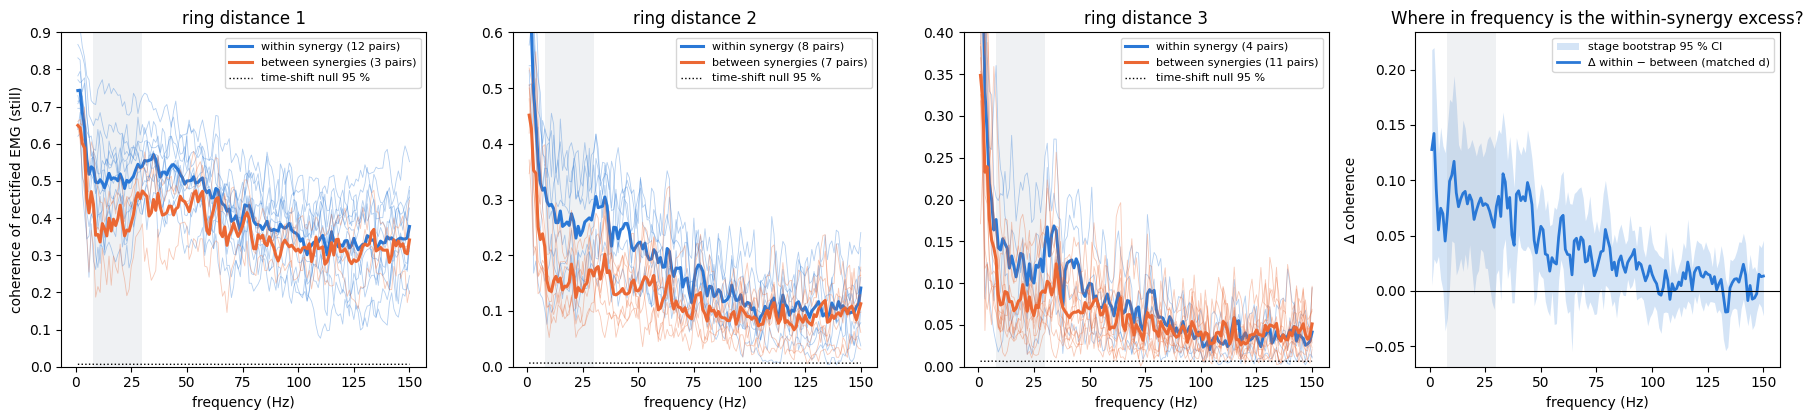

Δ by band: 2-6 Hz 0.087, 8-30 Hz 0.081, 31-45 Hz 0.082, 55-95 Hz 0.033, 100-150 Hz 0.008
'bump' = Δ(8-30) − Δ(2-6 and 31-45 Hz): -0.002 (95 % CI -0.013 to 0.008)


In [10]:
within_syn = groups_syn[IU[0]] == groups_syn[IU[1]]
spec_diff = matched_diff(pair_spec[: F_MAX + 1], groups_syn)
spec_ci = np.percentile(np.array([b[0] for b in boot_still["spec"]]), [2.5, 97.5], axis=0)
f_plot = freqs[1: F_MAX + 1]
fig, axs = plt.subplots(1, 4, figsize=(18, 4.3))
for ax, d in zip(axs[:3], [1, 2, 3]):
    for m, col, lab in [((DIST == d) & within_syn, BLUE, "within synergy"), ((DIST == d) & ~within_syn, ORANGE, "between synergies")]:
        ax.plot(f_plot, pair_spec[1: F_MAX + 1][:, m], color=col, lw=0.6, alpha=0.35)
        ax.plot(f_plot, pair_spec[1: F_MAX + 1][:, m].mean(1), color=col, lw=2.2, label=f"{lab} ({m.sum()} pairs)")
    ax.plot(f_plot, null95[1: F_MAX + 1], ":", color="k", lw=1, label="time-shift null 95 %")
    ax.axvspan(*BAND, color=GREY, alpha=0.15, lw=0)
    ax.set_ylim(0, 0.9 if d == 1 else (0.6 if d == 2 else 0.4)); ax.set_xlabel("frequency (Hz)")
    ax.set_title(f"ring distance {d}"); ax.legend(fontsize=8)
axs[0].set_ylabel("coherence of rectified EMG (still)")
ax = axs[3]
ax.fill_between(f_plot, spec_ci[0][1:], spec_ci[1][1:], color=BLUE, alpha=0.2, lw=0, label="stage bootstrap 95 % CI")
ax.plot(f_plot, spec_diff[1:], color=BLUE, lw=2, label="Δ within − between (matched d)")
ax.axhline(0, color="k", lw=0.8); ax.axvspan(*BAND, color=GREY, alpha=0.15, lw=0)
ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("Δ coherence"); ax.set_title("Where in frequency is the within-synergy excess?")
ax.legend(fontsize=8)
plt.tight_layout(); save(fig, "within_between_spectra"); plt.show()
bump = spec_diff[8:31].mean() - np.r_[spec_diff[2:7], spec_diff[31:46]].mean()
print(f"Δ by band: 2-6 Hz {spec_diff[2:7].mean():.3f}, 8-30 Hz {spec_diff[8:31].mean():.3f}, 31-45 Hz {spec_diff[31:46].mean():.3f}, "
      f"55-95 Hz {spec_diff[55:96].mean():.3f}, 100-150 Hz {spec_diff[100:151].mean():.3f}")
bump_bs = np.array([b[0][8:31].mean() - np.r_[b[0][2:7], b[0][31:46]].mean() for b in boot_still["spec"]])
print(f"'bump' = Δ(8-30) − Δ(2-6 and 31-45 Hz): {bump:.3f} (95 % CI {np.percentile(bump_bs, 2.5):.3f} to {np.percentile(bump_bs, 97.5):.3f})")

**What we see.**

- **Yes, within-synergy pairs share more 8-30 Hz coherence at the same distance.** Δ = 0.081 (95 % CI 0.022 to
  0.140; for scale, coherence at d = 2 is ~0.21). The synergy partition has the **largest Δ of all 660 contiguous
  partitions** of the ring (p = 0.002).
- **The crosstalk yardsticks do not show it.** On the raw-signal crosstalk index Δ = 0.015 (CI −0.010 to 0.045,
  p = 0.25), on the rectified 100-200 Hz coherence Δ = 0.006 (p = 0.37). At equal distance, within- and
  between-synergy pairs are about equally coupled electrically, yet the within pairs share much more slow and
  mid-frequency envelope modulation. The "excess" (8-30 minus 100-200 Hz) gives the same answer (Δ = 0.075,
  p = 0.003).
- **But it is not an alpha/beta signature.** The difference spectrum is flat from 2 to 45 Hz (Δ = 0.087 at
  2-6 Hz, 0.081 at 8-30 Hz, 0.082 at 31-45 Hz), then fades (0.033 at 55-95 Hz, 0.008 at 100-150 Hz). The "bump"
  index Δ(8-30) − Δ(flanks) is −0.002 (CI −0.013 to 0.008): no band preference. In the table the 1-5 Hz and
  30-45 Hz bands are as large and as significant as 8-30 Hz. The excess is **low-pass, not band-limited**.

### Matching on the measured crosstalk instead of the distance

Each pair's 8-30 Hz coherence against its crosstalk index (left). If crosstalk explained everything, within- and
between-synergy pairs would lie on one curve. We fit z(C₈₋₃₀) = a + b·z(XT) + c·z(XT)² + g·[within] on the 60
pairs with d ≤ 4 (z = atanh √C, a variance-stabilising transform); g is the within-synergy excess at equal
crosstalk. Right: Δ at 8-30 Hz for every contiguous 4-sector partition of the ring (the null), with the synergy
partition marked.

within-synergy effect at equal crosstalk: g = 0.115 z-units (95 % CI 0.056 to 0.173); contiguous-partition null p = 0.033


same with the rectified 100-200 Hz coherence as crosstalk measure: g = 0.135; null p = 0.008


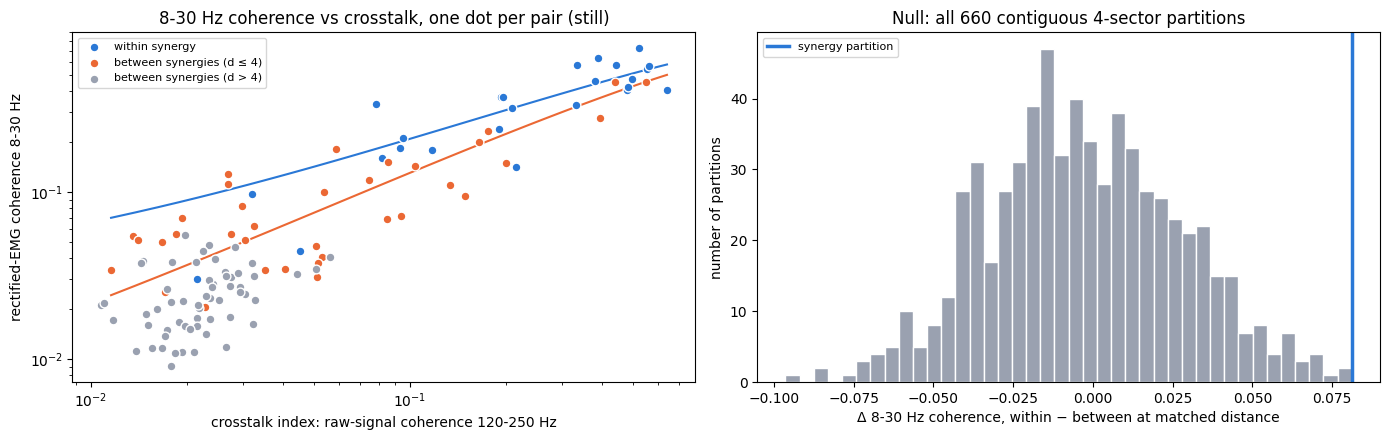

synergy partition Δ = 0.081; rank among 660 partitions: 1


In [11]:
q_still = pair_quantities(C_st, Cw_st)
v830 = q_still["rectified 8-30 Hz"]
g_obs = crosstalk_adjusted(v830, XT, groups_syn)
g_bs = np.array([b[0] for b in boot_still["adj"]])
g_null = np.array([crosstalk_adjusted(v830, XT, p) for p in parts4])
d830_null = np.array([matched_diff(v830, p) for p in parts4])
print(f"within-synergy effect at equal crosstalk: g = {g_obs:.3f} z-units (95 % CI {np.percentile(g_bs, 2.5):.3f} to "
      f"{np.percentile(g_bs, 97.5):.3f}); contiguous-partition null p = {(g_null >= g_obs).mean():.3f}")
# the same adjustment using the rectified 100-200 Hz coherence as the crosstalk measure
g_hf = crosstalk_adjusted(v830, q_still["rectified 100-200 Hz"], groups_syn)
print(f"same with the rectified 100-200 Hz coherence as crosstalk measure: g = {g_hf:.3f}; "
      f"null p = {(np.array([crosstalk_adjusted(v830, q_still['rectified 100-200 Hz'], p) for p in parts4]) >= g_hf).mean():.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
m4 = DIST <= 4
for m, col, lab in [(within_syn & m4, BLUE, "within synergy"), (~within_syn & m4, ORANGE, "between synergies (d ≤ 4)"),
                    (DIST > 4, GREY, "between synergies (d > 4)")]:
    ax1.scatter(XT[m], v830[m], s=40, color=col, edgecolor="white", linewidth=1, label=lab, zorder=3)
x = np.arctanh(np.sqrt(XT[m4])); z = np.arctanh(np.sqrt(v830[m4])); w = within_syn[m4].astype(float)
coef = np.linalg.lstsq(np.c_[np.ones(m4.sum()), x, x ** 2, w], z, rcond=None)[0]
xs = np.linspace(x.min(), x.max(), 100)
for gflag, col in [(0, ORANGE), (1, BLUE)]:
    ax1.plot(np.tanh(xs) ** 2, np.tanh(coef[0] + coef[1] * xs + coef[2] * xs ** 2 + coef[3] * gflag) ** 2, color=col, lw=1.5)
ax1.set_xscale("log"); ax1.set_yscale("log")
ax1.set_xlabel("crosstalk index: raw-signal coherence 120-250 Hz"); ax1.set_ylabel("rectified-EMG coherence 8-30 Hz")
ax1.set_title("8-30 Hz coherence vs crosstalk, one dot per pair (still)"); ax1.legend(fontsize=8)
ax2.hist(d830_null, bins=40, color=GREY, edgecolor="white")
ax2.axvline(matched_diff(v830, groups_syn), color=BLUE, lw=2.5, label="synergy partition")
ax2.set_xlabel("Δ 8-30 Hz coherence, within − between at matched distance"); ax2.set_ylabel("number of partitions")
ax2.set_title(f"Null: all {len(parts4)} contiguous 4-sector partitions"); ax2.legend(fontsize=8)
plt.tight_layout(); save(fig, "crosstalk_control"); plt.show()
print(f"synergy partition Δ = {matched_diff(v830, groups_syn):.3f}; rank among {len(parts4)} partitions: "
      f"{(d830_null > matched_diff(v830, groups_syn)).sum() + 1}")

**What we see.** At equal crosstalk index the within-synergy pairs still sit above the between-synergy pairs:
g = 0.115 z-units (CI 0.056 to 0.173), contiguous-partition null p = 0.033. This p is weaker than the
distance-matched one, partly because the crosstalk index flattens at ~0.02 beyond 3 spacings (section 4) and
ranks those pairs poorly. Using the rectified 100-200 Hz coherence as the crosstalk measure gives g = 0.135,
p = 0.008. Right: the synergy partition is the extreme of the null distribution (rank 1 of 660).

## 6. The anatomical split: palm (0-7) vs back (8-15)

Same statistic with two groups. Flexors and extensors are separate muscle groups with partly separate drive, but
they also co-contract. The null is every split of the ring into 2 contiguous halves of ≥ 4 electrodes.

In [12]:
res_anat = delta_table("still", groups_anat, 1, boot_still, parts2)
print(f"{len(parts2)} contiguous 2-sector partitions in the null")
print(res_anat.round(3).to_string())

72 contiguous 2-sector partitions in the null
                                  within (d≤4)  between (d≤4)  Δ matched  CI low  CI high  p (contiguous null)
quantity                                                                                                      
rectified 1-5 Hz                         0.457          0.235      0.082   0.031    0.118                0.097
rectified 8-15 Hz                        0.265          0.077      0.053   0.036    0.070                0.014
rectified 15-30 Hz                       0.254          0.085      0.034   0.017    0.055                0.028
rectified 8-30 Hz                        0.258          0.082      0.041   0.024    0.060                0.028
rectified 30-45 Hz                       0.264          0.096      0.029   0.015    0.044                0.028
rectified 55-95 Hz                       0.187          0.070      0.013   0.003    0.028                0.069
rectified 100-200 Hz                     0.146          0.068     

**What we see.** Same pattern, about half the size: Δ(8-30 Hz) = 0.041 (CI 0.024 to 0.060), p = 0.028 among
the 72 ways to cut the ring into two halves. Again nothing on the crosstalk measures (Δ = −0.008 raw, −0.003 at
100-200 Hz), and again the excess spreads over 1-45 Hz (largest at 1-15 Hz) instead of peaking at 8-30 Hz. Smaller is expected: each half merges two
synergies (and splits synergy 3), so "within-half" pairs include many between-synergy ones. Palm vs back is a
coarser version of the synergy map, not a competing one.

## 7. Still vs moving, and robustness checks

During fast movement the envelopes of many muscles rise and fall together with the movement itself, which can create
coherence at low frequencies that has nothing to do with oscillatory drive. Steady drive at 8-30 Hz, if present,
should be at least as visible in the still windows. Same number of windows in both conditions, so the noise level is
the same. Then three robustness checks for the main 8-30 Hz result: a stricter "still" threshold, and each hand alone.

fast windows, synergy groups:
                                  within (d≤4)  between (d≤4)  Δ matched  CI low  CI high  p (contiguous null)
quantity                                                                                                      
rectified 1-5 Hz                         0.552          0.314      0.069   0.016    0.107                0.176
rectified 8-15 Hz                        0.357          0.120      0.085   0.052    0.126                0.002
rectified 15-30 Hz                       0.315          0.089      0.070   0.048    0.107                0.009
rectified 8-30 Hz                        0.330          0.100      0.075   0.051    0.113                0.005
rectified 30-45 Hz                       0.305          0.081      0.059   0.039    0.093                0.008
rectified 55-95 Hz                       0.205          0.054      0.018   0.008    0.033                0.127
rectified 100-200 Hz                     0.194          0.057      0.005  -0.004  

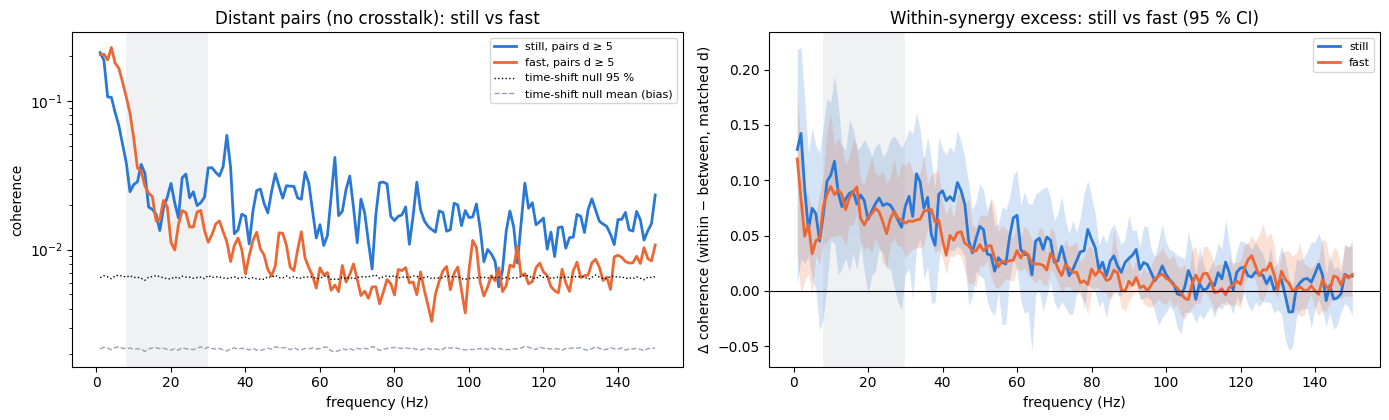

distant pairs (d ≥ 5), 8-30 Hz coherence: still 0.025, fast 0.027; null 95th pct of a single pair's band mean 0.0032
distant pairs significant at 8-30 Hz (vs the band null): still 100%, fast 100%


In [13]:
boot_fast = bootstrap("fast", [groups_syn, groups_anat])
res_fast = delta_table("fast", groups_syn, 0, boot_fast, parts4)
C_fa = data["fast"]["C"]
spec_diff_fast = matched_diff(C_fa[: F_MAX + 1, IU[0], IU[1]], groups_syn)
spec_ci_fast = np.percentile(np.array([b[0] for b in boot_fast["spec"]]), [2.5, 97.5], axis=0)
print("fast windows, synergy groups:")
print(res_fast.round(3).to_string())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.3))
far = DIST >= 5
for C, col, lab in [(C_st, BLUE, "still"), (C_fa, ORANGE, "fast")]:
    ax1.plot(f_plot, C[1: F_MAX + 1, IU[0][far], IU[1][far]].mean(1), color=col, lw=2, label=f"{lab}, pairs d ≥ 5")
ax1.plot(f_plot, null95[1: F_MAX + 1], ":", color="k", lw=1, label="time-shift null 95 %")
ax1.plot(f_plot, null_mean[1: F_MAX + 1], "--", color=GREY, lw=1, label="time-shift null mean (bias)")
ax1.axvspan(*BAND, color=GREY, alpha=0.15, lw=0); ax1.set_yscale("log")
ax1.set_xlabel("frequency (Hz)"); ax1.set_ylabel("coherence"); ax1.set_title("Distant pairs (no crosstalk): still vs fast")
ax1.legend(fontsize=8)
for sd, ci, col, lab in [(spec_diff, spec_ci, BLUE, "still"), (spec_diff_fast, spec_ci_fast, ORANGE, "fast")]:
    ax2.fill_between(f_plot, ci[0][1:], ci[1][1:], color=col, alpha=0.2, lw=0)
    ax2.plot(f_plot, sd[1:], color=col, lw=2, label=lab)
ax2.axhline(0, color="k", lw=0.8); ax2.axvspan(*BAND, color=GREY, alpha=0.15, lw=0)
ax2.set_xlabel("frequency (Hz)"); ax2.set_ylabel("Δ coherence (within − between, matched d)")
ax2.set_title("Within-synergy excess: still vs fast (95 % CI)"); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

far830 = {c: band_mean(data[c]["C"], *BAND)[far].mean() for c in ["still", "fast"]}
print(f"distant pairs (d ≥ 5), 8-30 Hz coherence: still {far830['still']:.3f}, fast {far830['fast']:.3f}; "
      f"null 95th pct of a single pair's band mean {null95_band:.4f}")
print(f"distant pairs significant at 8-30 Hz (vs the band null): still {(band_mean(C_st, *BAND)[far] > null95_band).mean():.0%}, "
      f"fast {(band_mean(C_fa, *BAND)[far] > null95_band).mean():.0%}")

In [14]:
robust = []
for lab, cond, side in [("still (main)", "still", None), (f"strict still (< {SPEED_STRICT} deg/s)", "strict", None),
                        ("still, left hand only", "still", "left"), ("still, right hand only", "still", "right"),
                        ("fast", "fast", None)]:
    d = data[cond]
    m = np.ones(len(d["meta"]), bool) if side is None else (d["meta"].side == side).values
    C = coherence(cross_spec(d["X"][m])); Cw = coherence(cross_spec(d["Xw"][m]))
    q = pair_quantities(C, Cw)
    robust.append({"condition": lab, "windows": m.sum(),
                   "Δ 8-30 Hz": matched_diff(q["rectified 8-30 Hz"], groups_syn),
                   "Δ 100-200 Hz": matched_diff(q["rectified 100-200 Hz"], groups_syn),
                   "Δ crosstalk index": matched_diff(q["raw 120-250 Hz (crosstalk index)"], groups_syn),
                   "g (equal crosstalk)": crosstalk_adjusted(q["rectified 8-30 Hz"], q["raw 120-250 Hz (crosstalk index)"], groups_syn),
                   "null p of Δ 8-30": (np.array([matched_diff(q["rectified 8-30 Hz"], p) for p in parts4])
                                        >= matched_diff(q["rectified 8-30 Hz"], groups_syn) - 1e-12).mean()})
robust = pd.DataFrame(robust).set_index("condition")
print(robust.round(3).to_string())

                            windows  Δ 8-30 Hz  Δ 100-200 Hz  Δ crosstalk index  g (equal crosstalk)  null p of Δ 8-30
condition                                                                                                             
still (main)                    459      0.081         0.006              0.015                0.115             0.002
strict still (< 150 deg/s)      132      0.065         0.024              0.031                0.104             0.003
still, left hand only           268      0.080         0.017              0.038                0.093             0.003
still, right hand only          191      0.081         0.002             -0.011                0.149             0.024
fast                            459      0.075         0.005             -0.003                0.131             0.005


**What we see.**

- **Movement does not remove the within-synergy excess.** Fast windows: Δ(8-30 Hz) = 0.075 (CI 0.051 to 0.113,
  p = 0.005), crosstalk index Δ = −0.003. The difference spectra of the still and fast windows lie on top of each
  other (right panel). Classical beta coherence is strongest in steady holds and suppressed during movement; this
  excess behaves differently.
- **Distant pairs** (no crosstalk to speak of): below 8 Hz both conditions are coherent (~0.2 at 1-3 Hz: whole-hand
  co-activation). Above ~30 Hz the still windows keep a floor of ~0.02 plus a 30-36 Hz peak, while the fast windows
  drop to ~0.01. A ~35 Hz component shared by all electrodes in slow windows could be a Piper-like rhythm or a device
  or interference artifact. It is the same for within and between pairs, so it says nothing about synergies.
- **Robustness.** Each hand alone gives the same Δ (left 0.080, right 0.081; g = 0.09 and 0.15; p ≤ 0.024). The
  strict "still" set (132 windows) gives Δ = 0.065 (p = 0.003), but there the crosstalk measures also lean towards
  within pairs (Δ = 0.031 raw, 0.024 at 100-200 Hz), so that subset is less clean.

## 8. The 16 × 16 coherence matrix: does clustering recover the synergies?

Three matrices from the still windows: 8-30 Hz coherence of the rectified EMG, the crosstalk index, and the 8-30 Hz
coherence **left over after removing what the crosstalk index predicts** (residual of a quadratic fit in z-units on all
120 pairs). Each is clustered into 4 groups (average linkage on 1 − similarity) and compared with the synergy groups
by the adjusted Rand index (ARI: 1 = same groups, 0 = chance). Because any contiguous grouping agrees partly with the
contiguous synergies, the reference is the ARI of the synergies with every contiguous 4-sector partition.

synergy groups:                 0001111222223333
                                               clusters  contiguous  ARI vs synergies  ARI vs palm/back  pct of contiguous partitions with lower ARI
matrix                                                                                                                                              
8-30 Hz coherence                      1111000223333333        True              0.44              0.54                                        71.97
crosstalk index (raw 120-250 Hz)       2233331111100000        True              0.51              0.29                                        82.73
8-30 Hz beyond crosstalk (z residual)  3330110122222222       False              0.43              0.64                                        70.76
ARI of the synergies with random contiguous 4-sector partitions: median 0.36, 95th pct 0.66
ARI between the 8-30 Hz clusters and the crosstalk clusters: 0.36


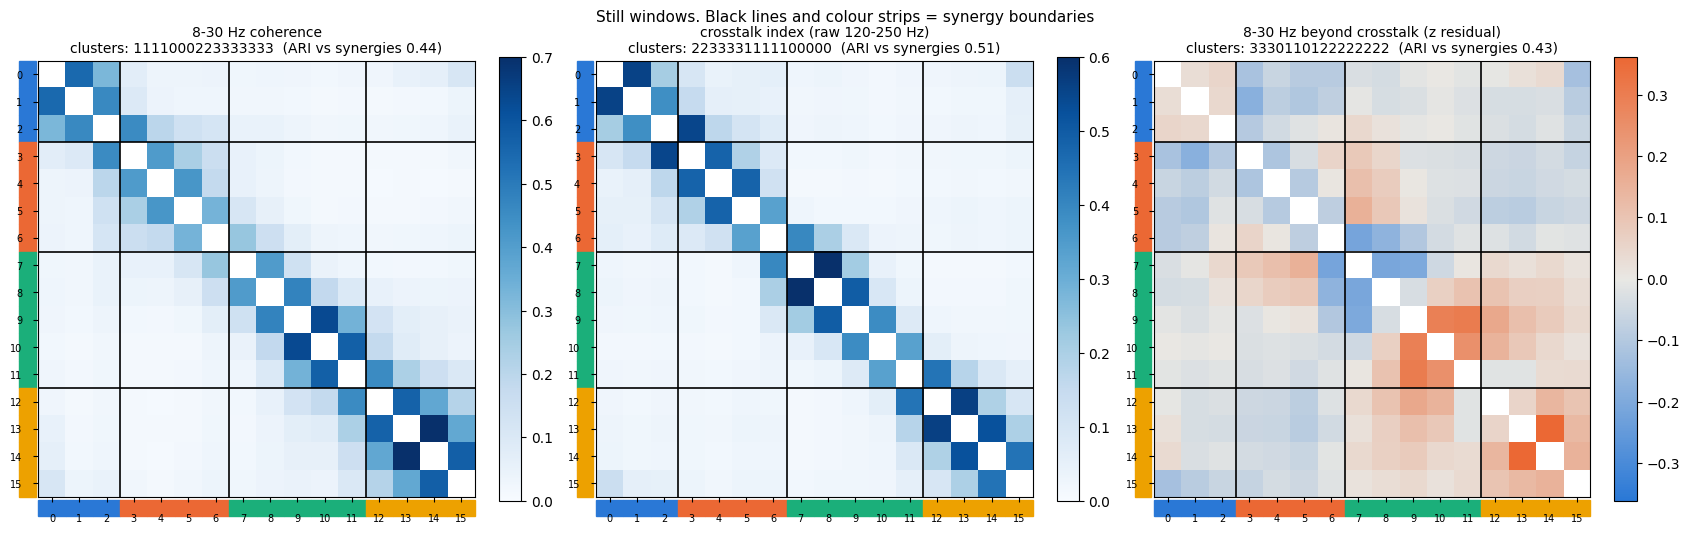

In [15]:
def to_matrix(v, diag=np.nan):
    M = np.full((16, 16), diag, dtype=float); M[IU] = v; M[IU[1], IU[0]] = v
    return M


def cluster(M, k=4):
    D = np.nanmax(M) - M
    np.fill_diagonal(D, 0)
    return fcluster(linkage(squareform(D, checks=False), "average"), k, "maxclust") - 1


def is_contiguous(lab):
    return (lab != np.roll(lab, 1)).sum() == len(np.unique(lab))


zx, zy = np.arctanh(np.sqrt(XT)), np.arctanh(np.sqrt(v830))
cfit = np.polyfit(zx, zy, 2)
resid = zy - np.polyval(cfit, zx)
mats = {"8-30 Hz coherence": to_matrix(v830, 1), "crosstalk index (raw 120-250 Hz)": to_matrix(XT, 1),
        "8-30 Hz beyond crosstalk (z residual)": to_matrix(resid, np.nan)}
ari_null = np.array([adjusted_rand_score(groups_syn, p) for p in parts4])
clusters, clus_rows = {}, []
for name, M in mats.items():
    lab = cluster(M if "residual" not in name else np.where(np.isnan(M), np.nanmax(M), M))
    clusters[name] = lab
    ari = adjusted_rand_score(groups_syn, lab)
    clus_rows.append({"matrix": name, "clusters": "".join(map(str, lab)), "contiguous": is_contiguous(lab),
                      "ARI vs synergies": ari, "ARI vs palm/back": adjusted_rand_score(groups_anat, lab),
                      "pct of contiguous partitions with lower ARI": (ari_null < ari).mean() * 100})
clus = pd.DataFrame(clus_rows).set_index("matrix")
print("synergy groups:                ", "".join(map(str, groups_syn)))
print(clus.round(2).to_string())
print(f"ARI of the synergies with random contiguous 4-sector partitions: median {np.median(ari_null):.2f}, "
      f"95th pct {np.percentile(ari_null, 95):.2f}")
print(f"ARI between the 8-30 Hz clusters and the crosstalk clusters: "
      f"{adjusted_rand_score(clusters['8-30 Hz coherence'], clusters['crosstalk index (raw 120-250 Hz)']):.2f}")

fig, axs = plt.subplots(1, 3, figsize=(17, 5.2))
bounds = np.flatnonzero(np.diff(groups_syn)) + 0.5
for ax, (name, M) in zip(axs, mats.items()):
    if "residual" in name:
        lim = np.nanmax(np.abs(M)); im = ax.imshow(M, cmap=DIVERGING, vmin=-lim, vmax=lim)
    else:
        im = ax.imshow(np.where(np.eye(16, dtype=bool), np.nan, M), cmap="Blues", vmin=0, vmax=0.7 if "8-30" in name else 0.6)
    for b in bounds:
        ax.axhline(b, color="k", lw=1.2); ax.axvline(b, color="k", lw=1.2)
    for c in range(16):                                   # synergy colour strip on the axes
        ax.add_patch(plt.Rectangle((c - 0.5, 15.6), 1, 0.6, color=GROUP_COLORS[groups_syn[c]], clip_on=False))
        ax.add_patch(plt.Rectangle((-1.2, c - 0.5), 0.6, 1, color=GROUP_COLORS[groups_syn[c]], clip_on=False))
    lab = clusters[name]
    ax.set_title(f"{name}\nclusters: {''.join(map(str, lab))}  (ARI vs synergies {adjusted_rand_score(groups_syn, lab):.2f})", fontsize=10)
    ax.set_xticks(range(16)); ax.set_yticks(range(16)); ax.tick_params(labelsize=7, pad=8)
    plt.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle("Still windows. Black lines and colour strips = synergy boundaries", fontsize=11)
plt.tight_layout(); save(fig, "matrix_clusters"); plt.show()

**What we see.**

- **Clustering does not recover the synergies better than crosstalk or a random contiguous split.** The 8-30 Hz
  matrix gives contiguous clusters {0-3}, {4-6}, {7-8}, {9-15} (ARI 0.44), better than only 72 % of random
  contiguous partitions (median ARI 0.36, 95th percentile 0.66). The crosstalk matrix alone does as well (ARI 0.51).
  Complete and weighted linkage give the same picture (ARI 0.44-0.46 for 8-30 Hz, 0.38-0.51 for crosstalk).
- Both matrices are a band along the diagonal (strong neighbour coupling decaying with distance), so hierarchical
  clustering mostly decides where to cut a chain, and small differences move the cuts. The matched within/between
  test of section 5 is the sensitive measure; clustering is not.
- **What remains after removing crosstalk** (right) is not cleanly block-diagonal: the strongest positive residuals
  are inside synergy 4 (12-15) and synergy 3 (9-11), but also across two boundaries (3-6 with 7-8, 9-11 with
  12-14). Clustering it gives non-contiguous groups (ARI 0.43).

## 9. Summary

(Numbers from this run.)

In [16]:
def row(name, res, key):
    r = res.loc[key]
    return {"test": name, "value": f"Δ = {r['Δ matched']:.3f} [{r['CI low']:.3f}, {r['CI high']:.3f}]",
            "null p": f"{r['p (contiguous null)']:.3f}"}


summary = pd.DataFrame([
    row("synergy: 8-30 Hz coherence, matched distance (still)", res_syn, "rectified 8-30 Hz"),
    row("synergy: 100-200 Hz coherence (crosstalk floor)", res_syn, "rectified 100-200 Hz"),
    row("synergy: raw-signal crosstalk index", res_syn, "raw 120-250 Hz (crosstalk index)"),
    row("synergy: excess 8-30 minus 100-200 Hz", res_syn, "excess: 8-30 minus 100-200 Hz"),
    {"test": "synergy: 8-30 Hz at equal crosstalk index (g, z-units)",
     "value": f"g = {g_obs:.3f} [{np.percentile(g_bs, 2.5):.3f}, {np.percentile(g_bs, 97.5):.3f}]",
     "null p": f"{(g_null >= g_obs).mean():.3f}"},
    {"test": "spectral bump: Δ(8-30) − Δ(2-6 & 31-45 Hz)",
     "value": f"{bump:.3f} [{np.percentile(bump_bs, 2.5):.3f}, {np.percentile(bump_bs, 97.5):.3f}]", "null p": "-"},
    row("palm/back: 8-30 Hz coherence, matched distance", res_anat, "rectified 8-30 Hz"),
    row("synergy: 8-30 Hz coherence, fast windows", res_fast, "rectified 8-30 Hz"),
    {"test": "clustering of 8-30 Hz matrix vs synergies (ARI)", "value": f"{clus.iloc[0]['ARI vs synergies']:.2f}",
     "null p": f"{1 - clus.iloc[0]['pct of contiguous partitions with lower ARI'] / 100:.3f}"},
    {"test": "clustering of crosstalk matrix vs synergies (ARI)", "value": f"{clus.iloc[1]['ARI vs synergies']:.2f}",
     "null p": f"{1 - clus.iloc[1]['pct of contiguous partitions with lower ARI'] / 100:.3f}"},
]).set_index("test")
print(summary.to_string())

                                                                            value null p
test                                                                                    
synergy: 8-30 Hz coherence, matched distance (still)     Δ = 0.081 [0.022, 0.140]  0.002
synergy: 100-200 Hz coherence (crosstalk floor)         Δ = 0.006 [-0.014, 0.027]  0.365
synergy: raw-signal crosstalk index                     Δ = 0.015 [-0.010, 0.045]  0.252
synergy: excess 8-30 minus 100-200 Hz                    Δ = 0.075 [0.031, 0.115]  0.003
synergy: 8-30 Hz at equal crosstalk index (g, z-units)   g = 0.115 [0.056, 0.173]  0.033
spectral bump: Δ(8-30) − Δ(2-6 & 31-45 Hz)                 -0.002 [-0.013, 0.008]      -
palm/back: 8-30 Hz coherence, matched distance           Δ = 0.041 [0.024, 0.060]  0.028
synergy: 8-30 Hz coherence, fast windows                 Δ = 0.075 [0.051, 0.113]  0.005
clustering of 8-30 Hz matrix vs synergies (ARI)                              0.44  0.280
clustering of crossta

In [17]:
if OUT_DIR:
    sel = slice(0, 101)                                   # spectra exported at 1 Hz, 0-100 Hz
    spectra = {}
    for cond in ["still", "fast"]:
        C = data[cond]["C"][sel][:, IU[0], IU[1]]
        spectra[cond] = {f"d{d}_{lab}": C[:, (DIST == d) & (within_syn if lab == "within" else ~within_syn)].mean(1).round(4).tolist()
                         for d in [1, 2, 3] for lab in ["within", "between"]}
        spectra[cond]["far_d5plus"] = C[:, DIST >= 5].mean(1).round(4).tolist()
    export = {
        "description": "Intermuscular coherence of rectified wrist EMG (emg2pose mini, 1 user, both hands pooled)",
        "freqs_hz": freqs[sel].tolist(),
        "spectra": spectra,
        "diff_spectrum_within_minus_between": {
            "still": spec_diff[sel].round(4).tolist(), "still_ci": spec_ci[:, sel].round(4).tolist(),
            "fast": spec_diff_fast[sel].round(4).tolist(), "fast_ci": spec_ci_fast[:, sel].round(4).tolist()},
        "null": {"time_shift_mean": null_mean[sel].round(5).tolist(), "time_shift_95pct_single_pair": null95[sel].round(5).tolist(),
                 "band_8_30_95pct": float(null95_band), "theoretical_CL_per_bin": float(CL),
                 "L_windows": int(L_still), "L_effective": float(L_eff)},
        "matrices": {"coh_8_30_still": np.round(mats["8-30 Hz coherence"], 4).tolist(),
                     "coh_8_30_fast": np.round(to_matrix(band_mean(C_fa, *BAND), 1), 4).tolist(),
                     "crosstalk_index_raw_120_250": np.round(XT_mat, 4).tolist(),
                     "residual_8_30_beyond_crosstalk_z": np.round(np.nan_to_num(mats["8-30 Hz beyond crosstalk (z residual)"]), 4).tolist()},
        "groupings": {"synergy_k4": groups_syn.tolist(), "palm_back": groups_anat.tolist(),
                      "synergy_share": np.round(share, 3).tolist(),
                      **{f"clusters_{k}": v.tolist() for k, v in clusters.items()}},
        "ring": {"circumference_spacings": CIRC, "note": "gap between channels 15 and 0 counted as 2 electrode spacings"},
        "windows": {"speed_still_max_deg_s": float(SPEED_STILL), "speed_fast_min_deg_s": float(SPEED_FAST),
                    "n_still": int(n_still), "n_fast": int(n_still), "n_strict": int(len(data["strict"]["meta"])),
                    "per_stage": counts.to_dict()},
        "stats": {"synergy_still": res_syn.round(4).reset_index().to_dict("records"),
                  "palm_back_still": res_anat.round(4).reset_index().to_dict("records"),
                  "synergy_fast": res_fast.round(4).reset_index().to_dict("records"),
                  "crosstalk_adjusted_g": {"value": float(g_obs), "ci": np.percentile(g_bs, [2.5, 97.5]).tolist(),
                                           "null_p": float((g_null >= g_obs).mean())},
                  "bump": {"value": float(bump), "ci": np.percentile(bump_bs, [2.5, 97.5]).tolist()},
                  "robustness": robust.round(4).reset_index().to_dict("records"),
                  "clustering": clus.round(3).reset_index().to_dict("records"),
                  "ari_null_median": float(np.median(ari_null)), "ari_null_95": float(np.percentile(ari_null, 95)),
                  "distance_table_still": tab.round(4).reset_index().to_dict("records")},
    }
    with open(Path(OUT_DIR) / "coherence.json", "w") as fh:
        json.dump(export, fh, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
    print("saved", Path(OUT_DIR) / "coherence.json")

saved /tmp/claude-1000/-home-rodri-projects-emg2poseneuromatch-semg2pose/1ade1be6-b4fe-499e-92aa-350333fec649/scratchpad/agents/coherence.json


### What the analysis says (one person, so only as a direction)

| | result | verdict |
|---|---|---|
| within vs between synergy, matched distance, 8-30 Hz | Δ = 0.08 coherence, best of 660 contiguous partitions, both hands, still and fast | **excess present** |
| same on the crosstalk yardsticks (raw 120-250 Hz, rectified 100-200 Hz) | Δ ≈ 0.01, not significant | crosstalk measures do not explain it |
| matched on the crosstalk index | g = 0.115 z-units (CI 0.06-0.17), p = 0.03 | excess survives, weaker |
| spectral shape | flat excess from 1 to 45 Hz, gone by 100 Hz; no 8-30 Hz bump | **no alpha/beta signature** |
| still vs fast | same excess | not specific to steady contraction |
| palm/back split | Δ = 0.04, p = 0.03 | coarser version of the same map |
| clustering of the 8-30 Hz matrix | ARI 0.44, crosstalk matrix 0.51, random contiguous median 0.36 | **does not recover the synergies** |

**Interpretation.** Electrodes in the same synergy sector share more envelope co-modulation (0-45 Hz) than
electrodes in different sectors at the same distance and with the same raw-signal crosstalk. Crosstalk *as measured
by raw-signal coherence* does not explain that. But the signature that would point to shared **oscillatory
(alpha/beta) neural drive**, a bump at 8-30 Hz, is absent, and the excess does not depend on whether the hand moves.
Two explanations fit the data and this dataset cannot separate them:

1. **Broadband common synaptic input** to the motor neurons under each sector (the "common drive" of a motor
   neuron pool, which spans 0 to ~40 Hz). That is neural, but most likely **intramuscular**: a sector is roughly one
   muscle or a few neighbouring muscles, so it shows a shared pool, not a coordination of different muscles.
2. **Residual crosstalk that raw coherence underestimates.** If two electrodes over the same muscle see the same
   motor units with differently shaped action potentials, their raw signals are only moderately coherent, but their
   rectified envelopes are coherent at low frequencies (rectification is known to distort EMG coherence: Neto &
   Christou 2010; McClelland et al. 2012; Farina et al. 2013). The low-pass shape of the excess, fading by
   ~100 Hz, is what this mechanism predicts.

Either way, the coherence data do **not** show that the synergies are a neural coordination strategy beyond
anatomy. They show that the sectors behave like functional units at the motor-unit level, which anatomy (one muscle
per sector) predicts too.

**Caveats.**

- One user; tasks are dynamic, with no true steady holds ("still" = slowest 20 %, ~50 deg/s per joint), and the slow
  and fast windows come from different tasks.
- Some circularity: the synergies are defined from slow envelope co-variation (100 ms RMS at 50 Hz), and the excess
  we find is broadband down to 1 Hz. The 8-30 Hz part is not used by the NMF, but it looks like the fast tail of the
  same co-modulation that defines the synergies.
- Few pairs per cell (3 between-synergy pairs at distance 1, 4 within-synergy pairs at distance 3); hence the
  stage bootstrap and the partition null rather than per-pair tests. The bootstrap has only 11 stages.
- Both hands are pooled assuming the electrode indices map to the same anatomy (each hand alone gives the same Δ).
- A broadband coupling floor (~0.02) between distant electrodes, and a 30-36 Hz peak in slow windows, are shared
  by all pairs and unexplained (common-mode noise, far-field signal, or a global rhythm).

**Tests that could separate the two explanations.**

1. **Left-right hand coherence.** Both wrists were recorded at the same time, and crosstalk between the two arms is
   physically impossible. Coherence between matching sectors of the two hands (e.g. in `TwoHandedFreeStyle`) would be
   shared drive with no crosstalk confound at all.
2. **Motor-unit decomposition** of the 2 kHz signals and coherence between *spike trains* of units in different
   sectors (the standard way to measure common input without crosstalk, Farina & Negro 2015).
3. **Steady isometric holds** at a few force levels, where beta coherence is expected if it exists.
4. **Full dataset, per user**: does the excess appear in every person and line up with each person's own synergy
   boundaries?